# Hyperspectral Image Processing Workflow


A general-purpose pipeline for processing hyperspectral images (ENVI format) acquired with line-scan cameras (Specim FX10 VNIR, SWIR, etc.).
The workflow loads raw captures along with white and dark references, computes reflectance, segments samples, extracts mean spectra, and applies Multiplicative Scatter Correction (MSC).

This notebook supports **multiple sensors in a single run**: define each sensor in the `SENSORS` dictionary in the Configuration section and the pipeline will process them sequentially, saving results to separate subfolders under `output/`.

**Quick start**

1. In the **Configuration** cell, verify the `data_path` entries in `SENSORS` and adjust per-sensor settings if needed.
2. Organise your images following the layout described in the *Data Organisation* section.
3. Run all cells in order from top to bottom.
4. Results are saved to `output/<timestamp>/vnir/` and `output/<timestamp>/swir/`.

**Notebook structure**

| # | Section | Purpose |
|---|---------|---------|
| 1 | Setup | Import libraries |
| 2 | Configuration | Sensor paths and processing parameters |
| 3 | Data Organisation | Expected folder and file layout |
| 4 | Core Functions | Loading, preprocessing, segmentation, spectral extraction |
| 5 | Pipeline | Orchestrates the full processing run for all sensors |
| 6 | Results & Export | Saves outputs and displays summary |
| 7 | Troubleshooting | Common problems and solutions |

> For most users only the **Configuration** section needs editing.

**Important:** all samples within a single sensor batch must share the same wavelength axis. Samples from different sensors are processed in separate runs within the same notebook execution.


## 1. Setup

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import spectral
from spectral import envi
import matplotlib.pyplot as plt
from datetime import datetime
from scipy.ndimage import gaussian_filter, zoom
from skimage.restoration import richardson_lucy

spectral.settings.envi_support_nonlowercase_params = True

## 2. Configuration

Add one entry to `SENSORS` for each camera/sensor you want to process. Per-sensor settings (paths, cropping, deblurring) are defined inside each entry. Settings shared by all sensors (segmentation mode, visualisation) are defined separately below.


In [2]:
# ---------------------------------------------------------------------------
# Sensor configurations
# ---------------------------------------------------------------------------
# Each key defines one independent processing run.
# To process a single sensor, comment out or remove the other entry.
# Per-sensor settings (paths, cropping, deblurring) are defined here.
# ---------------------------------------------------------------------------
SENSORS = {
    "vnir": {
        # Path to the folder containing one subfolder per sample
        "data_path": os.path.join("..", "data", "VNIR"),

        # Border cropping: Specim FX10 produces highly reflective strips
        # at the image edges that interfere with Otsu thresholding.
        "crop_borders": True,
        "crop_top": 200,     # rows to remove from the top edge
        "crop_bottom": 200,  # rows to remove from the bottom edge

        # Richardson-Lucy deconvolution (disable unless images are blurry)
        "perform_deblurring": False,
        "deblur_sigma": 0.1,      # Gaussian PSF sigma
        "deblur_iterations": 5,   # more = sharper but noisier
    },
    "swir": {
        "data_path": os.path.join("..", "data", "SWIR"),
        "crop_borders": True,
        "crop_top": 0,
        "crop_bottom": 0,
        "perform_deblurring": False,
        "deblur_sigma": 0.1,
        "deblur_iterations": 5,
    },
}

# ---------------------------------------------------------------------------
# Shared settings — applied to all sensors
# ---------------------------------------------------------------------------
# Show before/after images for each processing step.
# Useful for debugging; disable for faster batch processing.
ENABLE_VISUALIZATION = True

# "single"   – keep only the largest region (e.g. one fish fillet)
# "multiple" – keep all regions above MIN_ROI_AREA (e.g. rice grains)
ROI_MODE = "single"
MIN_ROI_AREA = 50        # minimum contour area in pixels² (multiple mode only)
SEGMENTATION_MARGIN = 5  # pixel margin around the segmented bounding box

# ---------------------------------------------------------------------------
# Output root
# All sensors from one run share a timestamped folder:
#   output/<timestamp>/vnir/
#   output/<timestamp>/swir/
# This keeps runs isolated and never collides with the pre-computed
# 48-sample spectra files in output/spectra/ used by notebooks 2–4.
# ---------------------------------------------------------------------------
OUTPUT_ROOT = os.path.join("..", "output")
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

for sensor, cfg in SENSORS.items():
    out = os.path.join(OUTPUT_ROOT, RUN_TIMESTAMP, sensor)
    os.makedirs(out, exist_ok=True)
    print(f"{sensor.upper()} → {out}  (data: {cfg['data_path']})") 

VNIR → ..\output\20260309_213017\vnir  (data: ..\data\VNIR)
SWIR → ..\output\20260309_213017\swir  (data: ..\data\SWIR)


## 3. Data Organisation

Your files **must** follow the layout below for the notebook to locate them automatically.

```
data/                              ← DATA_PATH
├── sample_1/
│   └── capture/
│       ├── sample_1.hdr           ← raw image header
│       ├── sample_1.raw           ← raw image data
│       ├── WHITEREF_sample_1.hdr  ← white reference header
│       ├── WHITEREF_sample_1.raw  ← white reference data
│       ├── DARKREF_sample_1.hdr   ← dark reference header
│       └── DARKREF_sample_1.raw   ← dark reference data
├── sample_2/
│   └── capture/
│       └── ...
└── ...
```

**Naming rules**

- Each sample has its own folder.
- Inside each sample folder there must be a subfolder called `capture`.
- Raw files: `{name}.hdr` / `{name}.raw`
- White reference: `WHITEREF_{name}.hdr` / `WHITEREF_{name}.raw`
- Dark reference: `DARKREF_{name}.hdr` / `DARKREF_{name}.raw`
- The `{name}` part must match the parent folder name exactly.

## 4. Core Functions

### 4.1 Data Loading

In [3]:
def open_hyperspectral_image(file_path):
    """Load an ENVI hyperspectral image from disk.

    Parameters
    ----------
    file_path : str
        Path to the .hdr header file.

    Returns
    -------
    data : ndarray of shape (height, width, bands) or None
    wavelengths : list of float or None
    """
    try:
        img = envi.open(file_path)
        data = img.load()

        # Reorder to (height, width, bands) and flip columns for consistency.
        # Remove the flip if your data does not require it.
        data = data.transpose(1, 0, 2)[:, ::-1, :]

        wavelengths = img.metadata.get('Wavelength', None)
        if wavelengths:
            wavelengths = [float(w) for w in wavelengths]

        return data, wavelengths

    except Exception as e:
        print(f"  Error loading {file_path}: {e}")
        return None, None


def load_and_compute_reflectance(folder_path, sample_name):
    """Load raw, white and dark reference cubes and compute reflectance.

    Reflectance = (Raw - Dark) / (White - Dark)

    Parameters
    ----------
    folder_path : str
        Path to the folder containing the .hdr/.raw files.
    sample_name : str
        Base name shared by all files in this sample.

    Returns
    -------
    reflectance : ndarray of shape (height, width, bands) or None
        Reflectance cube clipped to [0, 1].
    wavelengths : list of float or None
    """
    paths = {
        'raw':   os.path.join(folder_path, f"{sample_name}.hdr"),
        'white': os.path.join(folder_path, f"WHITEREF_{sample_name}.hdr"),
        'dark':  os.path.join(folder_path, f"DARKREF_{sample_name}.hdr"),
    }

    for key, path in paths.items():
        if not os.path.isfile(path):
            print(f"  Missing {key} file: {path}")
            return None, None

    raw, wavelengths = open_hyperspectral_image(paths['raw'])
    white, _ = open_hyperspectral_image(paths['white'])
    dark, _  = open_hyperspectral_image(paths['dark'])

    if any(x is None for x in [raw, white, dark]):
        print("  Failed to load one or more image cubes.")
        return None, None

    # Resize references to match the raw image spatial dimensions
    _, raw_cols, _ = raw.shape
    _, ref_cols, _ = white.shape
    factor = (1.0, raw_cols / ref_cols, 1.0)
    white = zoom(white, factor, order=1)
    dark  = zoom(dark,  factor, order=1)

    if raw.shape != white.shape or raw.shape != dark.shape:
        raise ValueError(
            f"Dimension mismatch after resizing: raw {raw.shape}, "
            f"white {white.shape}, dark {dark.shape}"
        )

    denominator = white - dark
    denominator[denominator == 0] = 1e-6

    reflectance = np.clip((raw - dark) / denominator, 0, 1)
    return reflectance, wavelengths


### 4.2 Preprocessing

In [4]:
def crop_borders(cube, top=200, bottom=200):
    """Remove border rows from a hyperspectral cube.

    Some line-scan cameras produce highly reflective strips at the image
    edges that interfere with automatic thresholding.

    Parameters
    ----------
    cube : ndarray of shape (height, width, bands)
    top, bottom : int
        Number of pixel rows to remove from each edge.

    Returns
    -------
    ndarray
        Cropped cube of shape (height - top - bottom, width, bands).
    """
    h = cube.shape[0]
    if top + bottom >= h:
        raise ValueError(
            f"Crop size ({top}+{bottom}) exceeds image height ({h})"
        )
    return cube[top:h - bottom, :, :]


def gaussian_psf(size=5, sigma=1.0):
    """Generate a normalised 2-D Gaussian point-spread function.

    The PSF models the optical blur of the imaging system and is used as
    input to Richardson-Lucy deconvolution. The optimal *sigma* and
    *num_iter* depend on camera optics and acquisition conditions — there
    is no universal default. Experiment with different values and visually
    compare the deconvolved output to find what works best for your data.

    Parameters
    ----------
    size : int
        Kernel side length in pixels (should be odd).
    sigma : float
        Standard deviation of the Gaussian. Larger values model stronger
        blur. Typical starting range: 0.1 – 2.0.

    Returns
    -------
    psf : ndarray of shape (size, size)
        Normalised kernel (sums to 1).
    """
    psf = np.zeros((size, size))
    psf[size // 2, size // 2] = 1.0
    psf = gaussian_filter(psf, sigma=sigma)
    return psf / psf.sum()


def apply_richardson_lucy(image, psf, num_iter=15):
    """Apply Richardson-Lucy deconvolution band by band.

    Parameters
    ----------
    image : ndarray of shape (height, width, bands)
    psf : ndarray
        Point-spread function kernel.
    num_iter : int
        Number of iterations. Higher values sharpen the image but may
        amplify noise.

    Returns
    -------
    ndarray
        Deconvolved image, same shape as input.
    """
    result = np.zeros_like(image)
    for b in range(image.shape[2]):
        result[:, :, b] = richardson_lucy(image[:, :, b], psf, num_iter=num_iter)
    return result


def find_optimal_band(cube):
    """Return the band index with the highest mean reflectance.

    This band typically gives the best contrast for Otsu thresholding.
    """
    return int(np.argmax(np.mean(cube, axis=(0, 1))))


def create_sample_mask(cube, band=None):
    """Create a binary mask using Otsu thresholding on a single band.

    Parameters
    ----------
    cube : ndarray of shape (height, width, bands)
    band : int or None
        Band index to threshold. If None the band with the highest mean
        reflectance is selected automatically.

    Returns
    -------
    mask : ndarray of shape (height, width), dtype uint8
        Binary mask (0 = background, 255 = sample).
    """
    if band is None:
        band = find_optimal_band(cube)

    img = cube[:, :, band]
    img_u8 = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(img_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return mask


def segment_sample(cube, mask, margin=5, roi_mode="single", min_roi_area=50):
    """Segment the sample region(s) from the background.

    Parameters
    ----------
    cube : ndarray of shape (height, width, bands)
        Reflectance image with values in [0, 1].
    mask : ndarray of shape (height, width), dtype uint8
        Binary mask (0 or 255).
    margin : int
        Pixel margin added around the bounding box.
    roi_mode : {"single", "multiple"}
        ``"single"`` — keep only the largest contour (e.g. one fish fillet).
        ``"multiple"`` — keep all contours with area >= *min_roi_area*
        (e.g. multiple grains on a tray). The mean spectrum is computed
        over all retained regions jointly.
    min_roi_area : int
        Minimum contour area in pixels (used only in ``"multiple"`` mode).

    Returns
    -------
    segmented : ndarray
        Cropped cube containing only the sample region(s).
    roi_mask : ndarray
        Refined binary mask matching *segmented*.
    """
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        print("  Warning: no contours found; returning original image.")
        return cube.copy(), mask.copy()

    # Sort by area (largest first)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)
    roi_mask = np.zeros_like(mask, dtype=np.uint8)

    if roi_mode == "single":
        # Keep the largest contour whose polygon approximation has >= 5 vertices
        for c in contours:
            if len(cv2.approxPolyDP(c, 3, True)) >= 5:
                cv2.fillPoly(roi_mask, [c], 255)
                break
        else:
            # Fallback: use the largest contour regardless
            cv2.fillPoly(roi_mask, [contours[0]], 255)

    elif roi_mode == "multiple":
        for c in contours:
            if cv2.contourArea(c) >= min_roi_area:
                cv2.fillPoly(roi_mask, [c], 255)
    else:
        raise ValueError(f"roi_mode must be 'single' or 'multiple', got '{roi_mode}'")

    # Apply mask (element-wise multiply is correct for float arrays)
    filtered = cube * (roi_mask[:, :, np.newaxis] / 255.0)

    # Crop to bounding box of the combined mask
    coords = cv2.findNonZero(roi_mask)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        x = max(0, x - margin)
        y = max(0, y - margin)
        w = min(cube.shape[1] - x, w + 2 * margin)
        h = min(cube.shape[0] - y, h + 2 * margin)
        segmented = filtered[y:y+h, x:x+w]
        roi_mask  = roi_mask[y:y+h, x:x+w]
    else:
        segmented = filtered

    return segmented, roi_mask

### 4.3 Spectral Processing

In [5]:
def extract_mean_spectrum(cube, mask):
    """Compute the mean reflectance spectrum over all masked pixels.

    Parameters
    ----------
    cube : ndarray of shape (height, width, bands)
    mask : ndarray of shape (height, width)
        Non-zero pixels are included in the average.

    Returns
    -------
    spectrum : ndarray of shape (bands,)
    """
    pixels = cube[mask > 0]
    if pixels.size == 0:
        print("  Warning: mask is empty; returning zeros.")
        return np.zeros(cube.shape[2])
    return np.mean(pixels, axis=0)


def multiplicative_scatter_correction(spectra, reference=None):
    """Apply Multiplicative Scatter Correction (MSC).

    Each spectrum is linearly regressed against a reference spectrum and
    the fitted slope/intercept are used to remove multiplicative and
    additive scatter effects.

    Parameters
    ----------
    spectra : ndarray of shape (n_samples, n_wavelengths)
    reference : ndarray of shape (n_wavelengths,) or None
        If None the mean of *spectra* is used.

    Returns
    -------
    corrected : ndarray, same shape as *spectra*
    reference : ndarray of shape (n_wavelengths,)
        The reference spectrum used. Save this to apply the same
        correction to new data later.
    """
    if reference is None:
        reference = np.mean(spectra, axis=0)

    corrected = np.zeros_like(spectra)
    for i in range(spectra.shape[0]):
        coeffs = np.polyfit(reference, spectra[i], 1)
        corrected[i] = (spectra[i] - coeffs[1]) / coeffs[0]

    return corrected, reference

### 4.4 Visualisation

In [6]:
def visualize_step(original, processed, band=None, title=""):
    """Show original vs. processed image side by side (single band)."""
    if band is None:
        band = find_optimal_band(original)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    im1 = ax1.imshow(original[:, :, band], cmap='gray')
    ax1.set_title('Before')
    ax1.axis('off')
    fig.colorbar(im1, ax=ax1)

    im2 = ax2.imshow(processed[:, :, band], cmap='gray')
    ax2.set_title('After')
    ax2.axis('off')
    fig.colorbar(im2, ax=ax2)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_spectra(wavelengths, raw, corrected, title="", save_path=None):
    """Plot raw and MSC-corrected spectra."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    ax1.plot(wavelengths, raw.T, alpha=0.6)
    ax1.set_ylabel('Reflectance (a.u.)')
    ax1.set_title('Original spectra')
    ax1.grid(True, alpha=0.3)

    ax2.plot(wavelengths, corrected.T, alpha=0.6)
    ax2.set_xlabel('Wavelength (nm)')
    ax2.set_ylabel('Reflectance (a.u.)')
    ax2.set_title('MSC-corrected spectra')
    ax2.grid(True, alpha=0.3)

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

## 5. Processing Pipeline

In [7]:
def process_single_sample(sample_name, folder_path,
                          crop=False, crop_top=200, crop_bottom=200,
                          deblur=False, deblur_sigma=0.1, deblur_iter=5,
                          roi_mode="single", min_roi_area=50,
                          margin=5, visualize=False):
    """Run the full processing pipeline on one sample.

    Parameters
    ----------
    sample_name : str
    folder_path : str
        Path to the ``capture/`` folder.
    crop : bool
        Remove border rows before segmentation.
    crop_top, crop_bottom : int
        Rows to crop (only used when *crop* is True).
    deblur : bool
        Apply Richardson-Lucy deconvolution.
    deblur_sigma : float
        Gaussian PSF sigma for deconvolution.
    deblur_iter : int
        Number of deconvolution iterations.
    roi_mode : str
        Passed to ``segment_sample``.
    min_roi_area : int
        Passed to ``segment_sample``.
    margin : int
        Pixel margin around the segmented bounding box.
    visualize : bool
        Show intermediate figures.

    Returns
    -------
    spectrum : ndarray or None
    wavelengths : list or None
    """
    print(f"Processing: {sample_name}")

    # 1. Reflectance
    reflectance, wavelengths = load_and_compute_reflectance(folder_path, sample_name)
    if reflectance is None:
        return None, None

    # 2. Border cropping
    if crop:
        reflectance = crop_borders(reflectance, top=crop_top, bottom=crop_bottom)

    # 3. Deblurring
    if deblur:
        print("  Deblurring...")
        psf = gaussian_psf(sigma=deblur_sigma)
        processed = apply_richardson_lucy(reflectance, psf, num_iter=deblur_iter)
        if visualize:
            visualize_step(reflectance, processed, title=f"Deblurring — {sample_name}")
    else:
        processed = reflectance

    # 4. Mask & segmentation
    print("  Segmenting...")
    mask = create_sample_mask(processed)
    if visualize:
        plt.imshow(mask, cmap='gray')
        plt.title('Binary mask')
        plt.axis('off')
        plt.show()

    segmented, roi_mask = segment_sample(
        processed, mask, margin=margin,
        roi_mode=roi_mode, min_roi_area=min_roi_area,
    )
    if visualize:
        visualize_step(processed, segmented, title=f"Segmentation — {sample_name}")

    # 5. Mean spectrum
    spectrum = extract_mean_spectrum(segmented, roi_mask)
    print("  Done.")
    return spectrum, wavelengths


def process_all_samples(base_path, **kwargs):
    """Discover and process every sample folder under *base_path*.

    Parameters
    ----------
    base_path : str
    **kwargs
        Forwarded to ``process_single_sample``.

    Returns
    -------
    dict with keys ``spectra``, ``wavelengths``, ``sample_names``,
    or None if no samples were found.
    """
    folders = sorted([
        f for f in os.listdir(base_path)
        if os.path.isdir(os.path.join(base_path, f))
    ])

    if not folders:
        print(f"No sample folders found in {base_path}")
        return None

    print(f"Found {len(folders)} sample(s)\n")

    spectra, names = [], []
    wavelengths = None

    for i, name in enumerate(folders, 1):
        print(f"[{i}/{len(folders)}] ", end="")
        capture = os.path.join(base_path, name, "capture")

        if not os.path.isdir(capture):
            print(f"  Skipping {name}: no 'capture' subfolder.")
            continue

        spec, wl = process_single_sample(name, capture, **kwargs)
        if spec is not None:
            spectra.append(spec)
            names.append(name)
            if wavelengths is None:
                wavelengths = wl

    print(f"\nProcessed {len(spectra)}/{len(folders)} samples successfully.")

    return {
        'spectra': np.array(spectra) if spectra else np.array([]),
        'wavelengths': wavelengths,
        'sample_names': names,
    }

## 6. Results & Export

In [8]:
def save_results(results, output_dir, duration_seconds=None):
    """Save spectra, MSC reference, and processing summary to disk.

    Parameters
    ----------
    results : dict
        Output of ``process_all_samples``.
    output_dir : str
    duration_seconds : float or None
        Total wall-time (included in the summary CSV).
    """
    spectra    = results['spectra']
    wavelengths = results['wavelengths']
    names      = results['sample_names']

    os.makedirs(output_dir, exist_ok=True)

    # Original mean spectra
    df = pd.DataFrame(spectra, columns=wavelengths)
    df.insert(0, 'sample_name', names)
    path = os.path.join(output_dir, 'mean_spectra_original.csv')
    df.to_csv(path, index=False, sep=';')
    print(f"  Saved {path}")

    # MSC-corrected spectra
    spectra_msc, ref_spectrum = multiplicative_scatter_correction(spectra)
    df_msc = pd.DataFrame(spectra_msc, columns=wavelengths)
    df_msc.insert(0, 'sample_name', names)
    path = os.path.join(output_dir, 'mean_spectra_msc.csv')
    df_msc.to_csv(path, index=False, sep=';')
    print(f"  Saved {path}")

    # MSC reference spectrum (needed to apply the same correction to new data)
    df_ref = pd.DataFrame({'Intensity': ref_spectrum}, index=wavelengths)
    path = os.path.join(output_dir, 'msc_reference.csv')
    df_ref.to_csv(path)
    print(f"  Saved {path}")

    # Spectra comparison plot
    plot_path = os.path.join(output_dir, 'spectra_comparison.png')
    plot_spectra(
        wavelengths, spectra, spectra_msc,
        title=f"Mean spectra — {len(names)} samples",
        save_path=plot_path,
    )
    print(f"  Saved {plot_path}")

    # Processing summary
    summary = {
        'Samples processed': len(names),
        'Number of bands': len(wavelengths),
        'Wavelength range (nm)': f"{wavelengths[0]:.1f} – {wavelengths[-1]:.1f}",
        'Processing date': datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    }
    if duration_seconds is not None:
        minutes, seconds = divmod(int(duration_seconds), 60)
        summary['Processing duration'] = f"{minutes}m {seconds}s"

    summary_df = pd.DataFrame(list(summary.items()), columns=['Parameter', 'Value'])
    path = os.path.join(output_dir, 'processing_summary.csv')
    summary_df.to_csv(path, index=False, sep=';')
    print(f"  Saved {path}")

### Run — process all sensors


  Sensor : VNIR
  Data   : ..\data\VNIR
  Output : ..\output\20260309_213017\vnir
Found 6 sample(s)

[1/6] Processing: FX10__1-C-24h
  Segmenting...


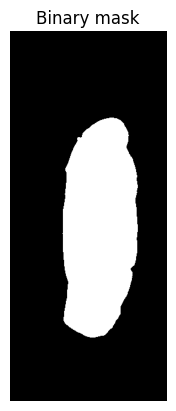

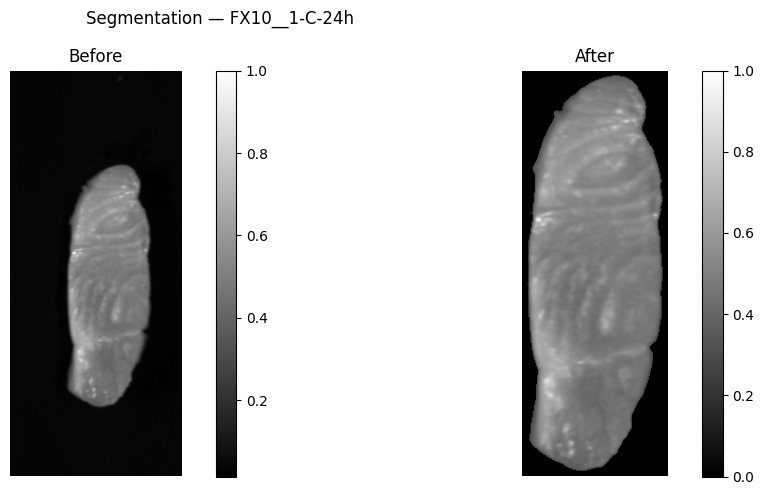

  Done.
[2/6] Processing: FX10__1-K-24h
  Segmenting...


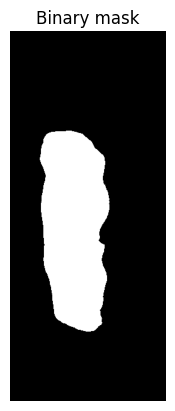

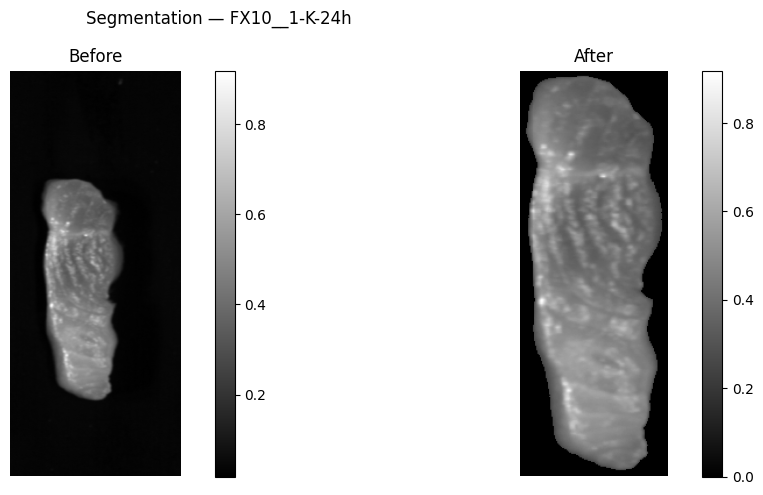

  Done.
[3/6] Processing: FX10__14-C-24H
  Segmenting...


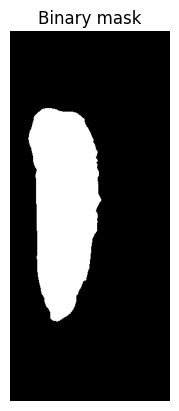

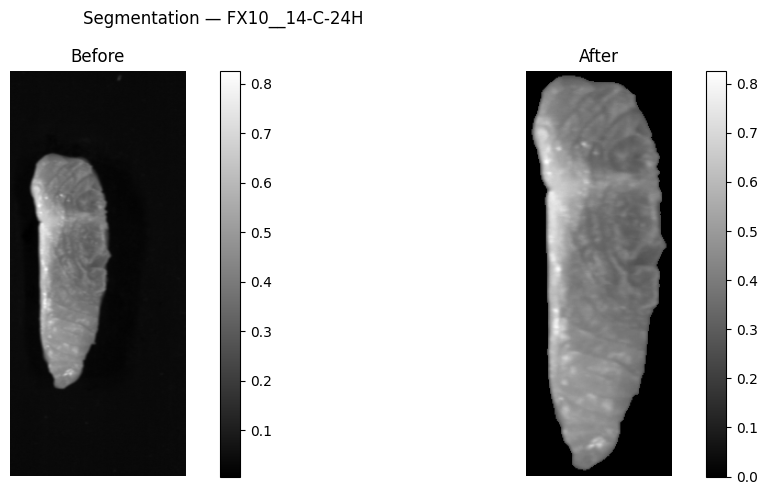

  Done.
[4/6] Processing: FX10__14-K-24H
  Segmenting...


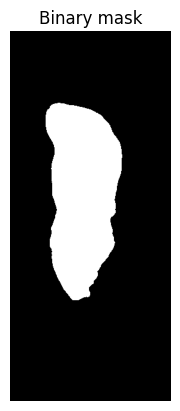

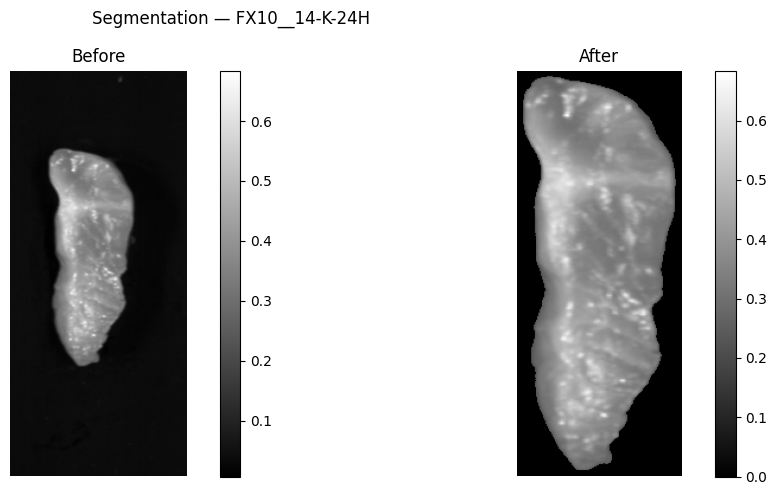

  Done.
[5/6] Processing: FX10__6-C-24H
  Segmenting...


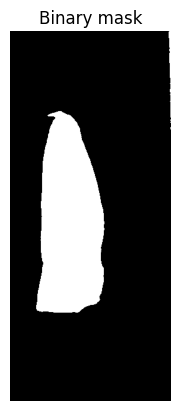

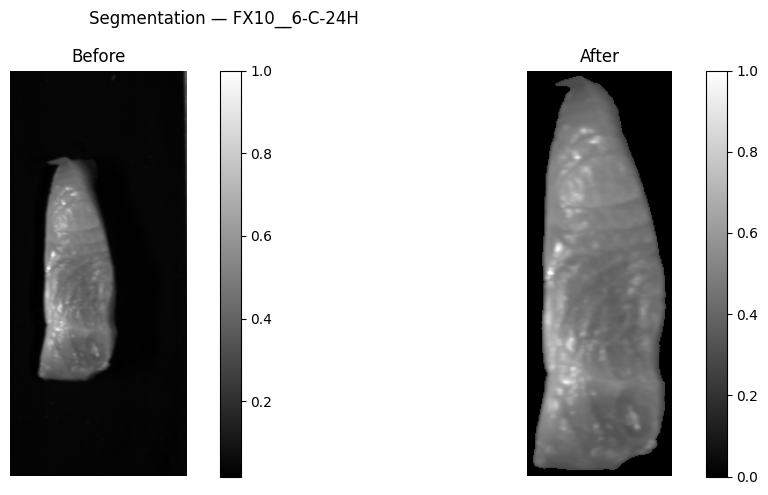

  Done.
[6/6] Processing: FX10__6-K-24H
  Segmenting...


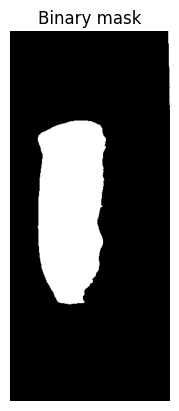

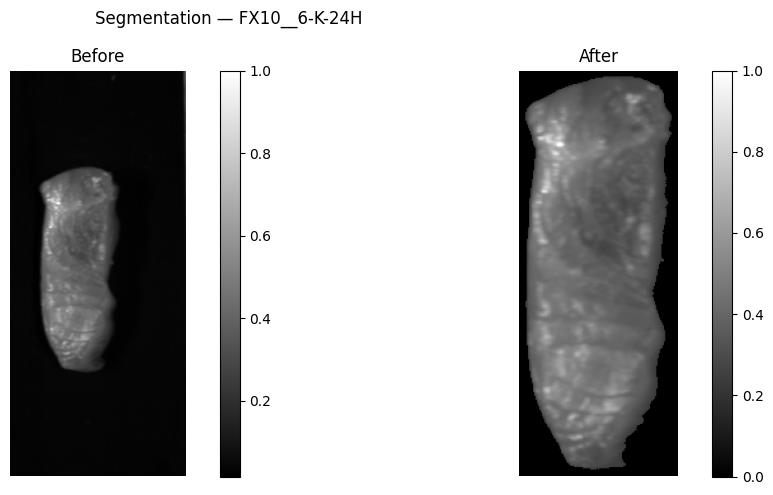

  Done.

Processed 6/6 samples successfully.
  Saved ..\output\20260309_213017\vnir\mean_spectra_original.csv
  Saved ..\output\20260309_213017\vnir\mean_spectra_msc.csv
  Saved ..\output\20260309_213017\vnir\msc_reference.csv


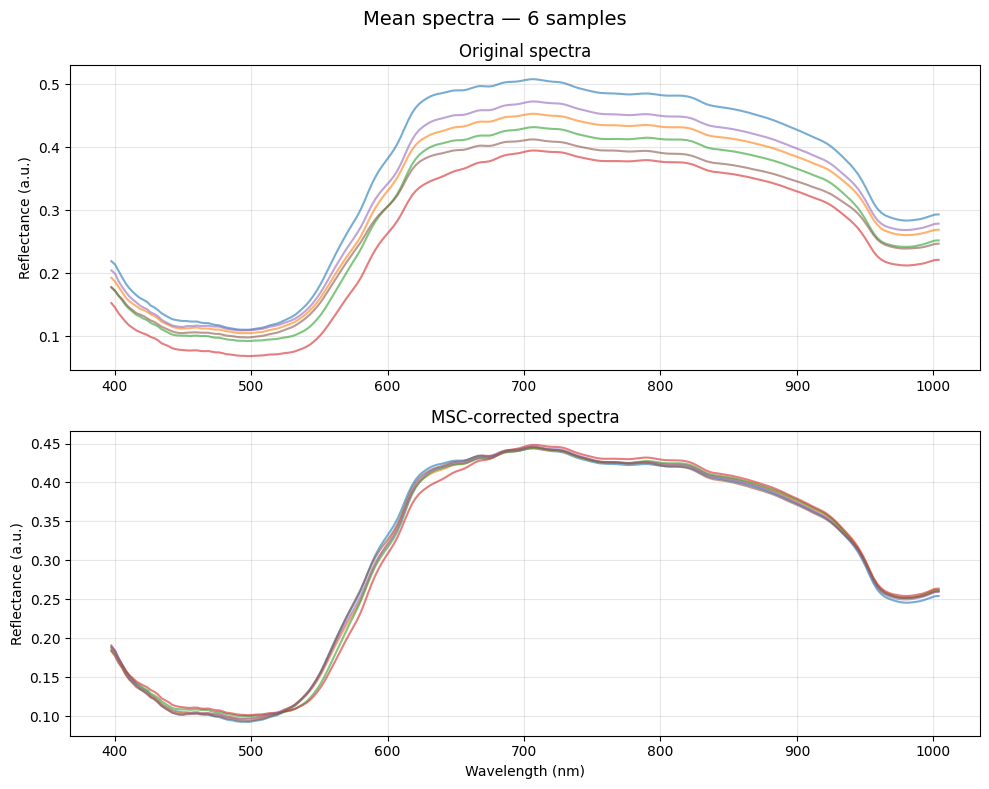

  Saved ..\output\20260309_213017\vnir\spectra_comparison.png
  Saved ..\output\20260309_213017\vnir\processing_summary.csv

VNIR done in 122.1s  →  ..\output\20260309_213017\vnir

  Sensor : SWIR
  Data   : ..\data\SWIR
  Output : ..\output\20260309_213017\swir
Found 6 sample(s)

[1/6] Processing: SWIR__1-C-24H
  Segmenting...


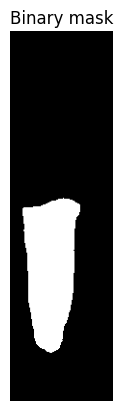

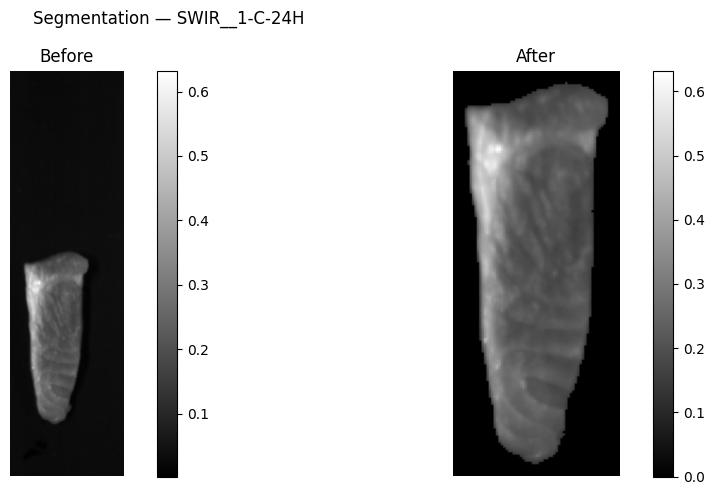

  Done.
[2/6] Processing: SWIR__1-K-24H
  Segmenting...


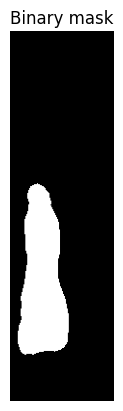

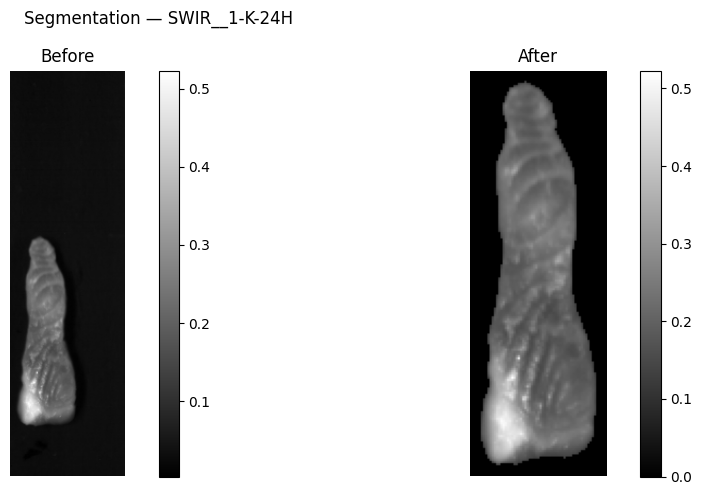

  Done.
[3/6] Processing: SWIR__14-C-24H
  Segmenting...


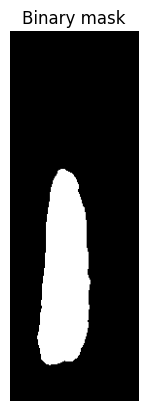

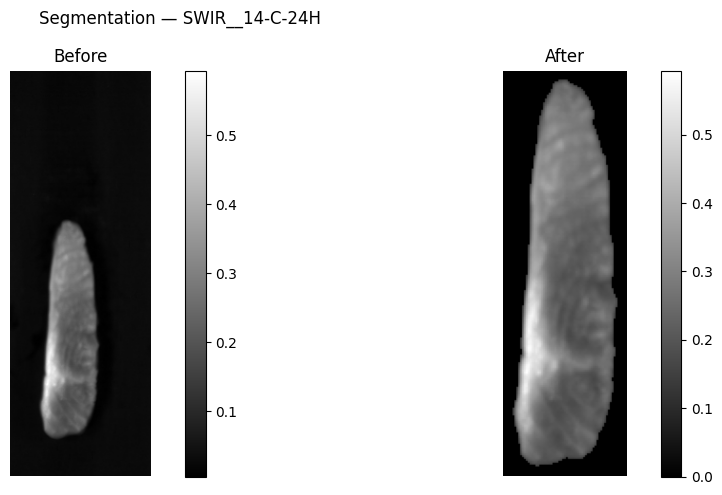

  Done.
[4/6] Processing: SWIR__14-K-24H
  Segmenting...


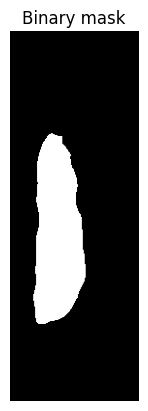

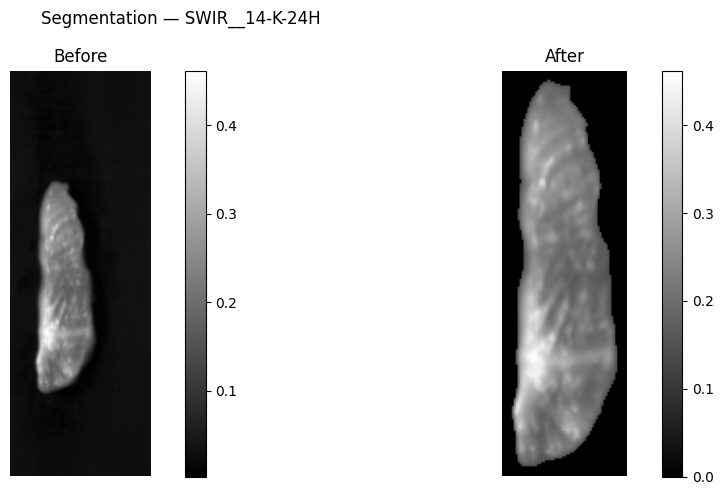

  Done.
[5/6] Processing: SWIR__6-C-24H
  Segmenting...


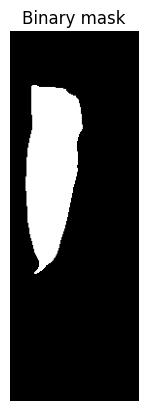

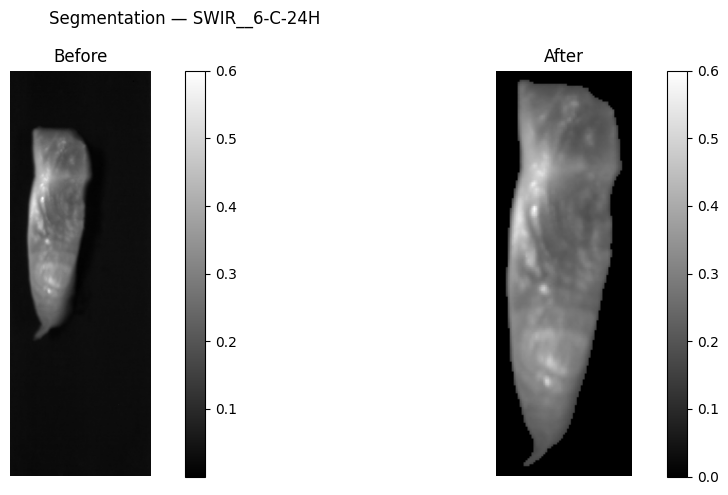

  Done.
[6/6] Processing: SWIR__6-K-24H
  Segmenting...


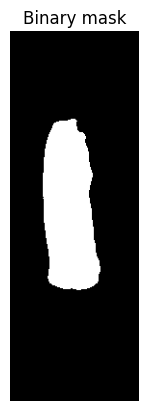

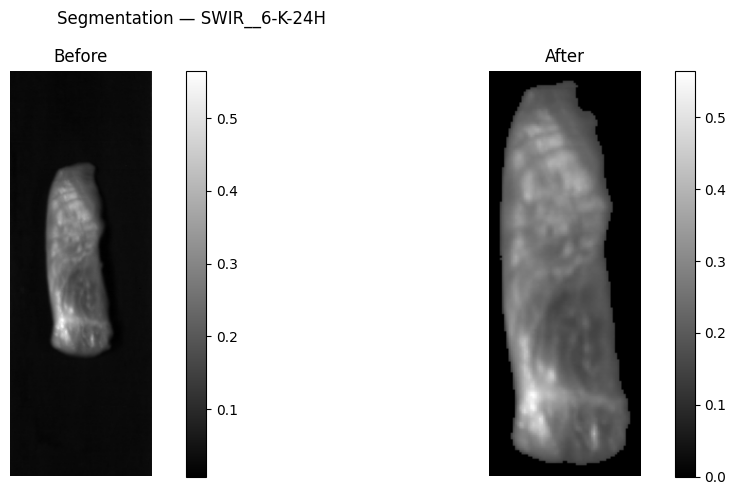

  Done.

Processed 6/6 samples successfully.
  Saved ..\output\20260309_213017\swir\mean_spectra_original.csv
  Saved ..\output\20260309_213017\swir\mean_spectra_msc.csv
  Saved ..\output\20260309_213017\swir\msc_reference.csv


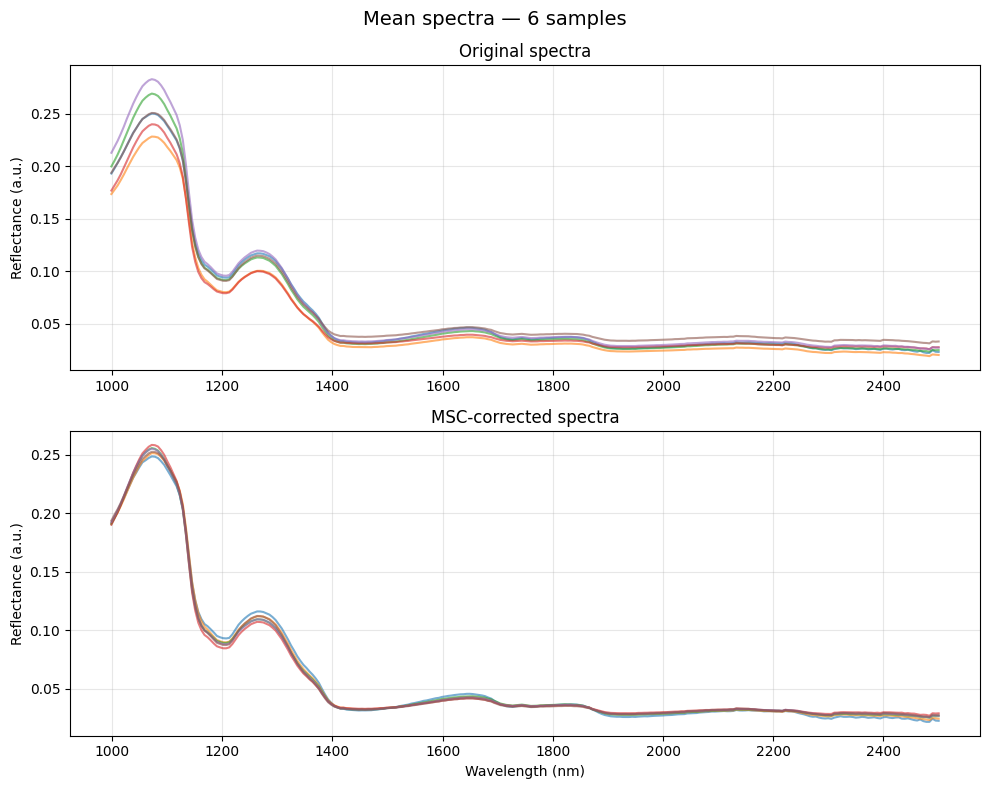

  Saved ..\output\20260309_213017\swir\spectra_comparison.png
  Saved ..\output\20260309_213017\swir\processing_summary.csv

SWIR done in 34.0s  →  ..\output\20260309_213017\swir



In [9]:
all_results = {}

for sensor_name, cfg in SENSORS.items():
    output_dir = os.path.join(OUTPUT_ROOT, RUN_TIMESTAMP, sensor_name)

    print("=" * 60)
    print(f"  Sensor : {sensor_name.upper()}")
    print(f"  Data   : {cfg['data_path']}")
    print(f"  Output : {output_dir}")
    print("=" * 60)

    t_start = time.time()

    results = process_all_samples(
        cfg["data_path"],
        crop=cfg["crop_borders"],
        crop_top=cfg["crop_top"],
        crop_bottom=cfg["crop_bottom"],
        deblur=cfg["perform_deblurring"],
        deblur_sigma=cfg["deblur_sigma"],
        deblur_iter=cfg["deblur_iterations"],
        roi_mode=ROI_MODE,
        min_roi_area=MIN_ROI_AREA,
        margin=SEGMENTATION_MARGIN,
        visualize=ENABLE_VISUALIZATION,
    )

    duration = time.time() - t_start

    if results and results["spectra"].size > 0:
        save_results(results, output_dir, duration_seconds=duration)
        print(f"\n{sensor_name.upper()} done in {duration:.1f}s  →  {output_dir}\n")
    else:
        print(f"\nNo samples processed for {sensor_name.upper()}. "
              f"Check messages above.\n")

    all_results[sensor_name] = results


### Summary

In [10]:
for sensor_name, results in all_results.items():
    if results and results["spectra"].size > 0:
        wl = results["wavelengths"]
        print(f"\n{'─' * 40}")
        print(f"  {sensor_name.upper()}")
        print(f"{'─' * 40}")
        print(f"  Samples processed : {len(results['sample_names'])}")
        print(f"  Wavelength range  : {wl[0]:.1f} – {wl[-1]:.1f} nm")
        print(f"  Number of bands   : {len(wl)}")
        for i, name in enumerate(results["sample_names"], 1):
            print(f"    {i}. {name}")
    else:
        print(f"\n  {sensor_name.upper()}: no results.")



────────────────────────────────────────
  VNIR
────────────────────────────────────────
  Samples processed : 6
  Wavelength range  : 397.7 – 1003.8 nm
  Number of bands   : 224
    1. FX10__1-C-24h
    2. FX10__1-K-24h
    3. FX10__14-C-24H
    4. FX10__14-K-24H
    5. FX10__6-C-24H
    6. FX10__6-K-24H

────────────────────────────────────────
  SWIR
────────────────────────────────────────
  Samples processed : 6
  Wavelength range  : 998.8 – 2500.1 nm
  Number of bands   : 270
    1. SWIR__1-C-24H
    2. SWIR__1-K-24H
    3. SWIR__14-C-24H
    4. SWIR__14-K-24H
    5. SWIR__6-C-24H
    6. SWIR__6-K-24H


## 7. Troubleshooting

| Symptom | Likely cause | Fix |
|---------|-------------|-----|
| *"No sample folders found"* | `data_path` in `SENSORS` is wrong or the folder is empty. | Verify the path and check that each sample has its own subfolder. |
| *"Missing raw/white/dark file"* | One or more of the six required files is missing or misnamed. | Check that `WHITEREF_` / `DARKREF_` prefixes and the sample name match exactly. |
| *"No 'capture' subfolder"* | The internal folder structure is different. | Each sample folder must contain a subfolder named `capture`. |
| *"ValueError: setting an array element with a sequence"* | Samples have different numbers of bands (e.g. mixing SWIR and VNIR data in the same entry). | Keep each sensor in its own `SENSORS` entry — they are processed independently. |
| Poor segmentation | Otsu threshold fails on low-contrast images. | Set `ENABLE_VISUALIZATION = True`, inspect the mask, and try specifying a band manually in `create_sample_mask()`. |
| Blurry or noisy after deblurring | Sigma or iteration count is unsuitable for your data. | Adjust `deblur_sigma` and `deblur_iterations` in the sensor config, or set `perform_deblurring = False`. |
| Processing is too slow | Visualisation and/or deblurring add overhead. | Set `ENABLE_VISUALIZATION = False` and `perform_deblurring = False`. |
| Mean spectrum is all zeros (`roi_mode="multiple"`) | All contours are smaller than `MIN_ROI_AREA`. | Lower `MIN_ROI_AREA` — try `50` or `1` to include everything Otsu identified. |
